# Model Training & Evaluation: Gradient Boosting

**Team Member:** Mustafa

This notebook trains the ensemble boosting model (Gradient Boosting Classifier) on the fully cleaned and standardized dataset produced in `data_cleaning_merged.ipynb`. It evaluates the model strictly on the Validation set to avoid data leakage before final testing.

In [1]:
# Import necessary libraries for data manipulation and mathematical operations
import pandas as pd
import numpy as np

# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import the Gradient Boosting algorithm and evaluation metrics from scikit-learn
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Configure visual aesthetics for professional graphing
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

## 1. Data Loading
We load the strictly partitioned subsets from the `Data/` directory. For this iteration, we only use `X_train` / `y_train` for model fitting, and `X_val` / `y_val` for intermediate evaluation.

In [2]:
# -------------------------------------------------------------------------
# Load Processed Training and Validation Sets
# -------------------------------------------------------------------------
# Define the relative path to the preprocessed data directory
base_path = "../Data/"

# Load the predictor features (X) for the training subset
X_train = pd.read_csv(f"{base_path}processed_X_train.csv")

# Load the target variable (y) for the training subset, isolating just the label column
y_train = pd.read_csv(f"{base_path}processed_y_train.csv")['Layoff_Risk']

# Load the predictor features (X) for the validation subset
X_val = pd.read_csv(f"{base_path}processed_X_val.csv")

# Load the target variable (y) for the validation subset, isolating just the label column
y_val = pd.read_csv(f"{base_path}processed_y_val.csv")['Layoff_Risk']

# Print the dimensionality to verify successful loading
print(f"Training set: {X_train.shape[0]:,} rows")
print(f"Validation set: {X_val.shape[0]:,} rows")

Training set: 14,000 rows
Validation set: 3,000 rows


> **Methodological Rule — Zero-Leakage Training:**
> The model is exposed solely to the 14,000 training records. Evaluation is conducted solely against the 3,000 validation records. The test set remains completely unseen.

## 2. Model Initialization and Training

In [3]:
# -------------------------------------------------------------------------
# Fit Gradient Boosting Classifier
# -------------------------------------------------------------------------
# We initialize the Gradient Boosting Classifier ensemble algorithm.
# We set random_state=42 to ensure the exact same trees are built every time 
# the code is run, enabling deterministic and reproducible results.
gbc = GradientBoostingClassifier(random_state=42)

# Fit the ensemble of decision trees strictly to the training partition.
gbc.fit(X_train, y_train)

print("Gradient Boosting training completed successfully!")

Gradient Boosting training completed successfully!


## 3. Validation Performance & Metrics

Because this is a multi-class classification problem (0: Low, 1: Medium, 2: High), we calculate:
- **Overall Accuracy**
- **Sensitivity (Recall)**: Calculated per class and as a macro average.
- **Specificity (True Negative Rate)**: Calculated per class and as a macro average.

In [4]:
# -------------------------------------------------------------------------
# Predict on Validation Set
# -------------------------------------------------------------------------
# Generate predicted class labels for the validation subset
y_pred = gbc.predict(X_val)

# Calculate the overall proportion of correct predictions across all classes
acc = accuracy_score(y_val, y_pred)
print(f"Validation Accuracy: {acc:.4f}\n")

# Generate a confusion matrix to evaluate class-level true positives, false positives, etc.
cm = confusion_matrix(y_val, y_pred)

# Define the categorical class labels for clean iteration and printing
classes = [0, 1, 2]
class_names = ['Low (0)', 'Medium (1)', 'High (2)']

print("--- Metric Evaluation ---")
sensitivities = []
specificities = []

# Iterate through each unique class to calculate One-vs-Rest metrics
for i, label in enumerate(classes):
    # True Positives: diagonal element for the current class
    tp = cm[i, i]
    
    # False Negatives: sum of actual class row minus true positives
    fn = cm[i, :].sum() - tp
    
    # False Positives: sum of predicted class column minus true positives
    fp = cm[:, i].sum() - tp
    
    # True Negatives: total observations minus (TP + FP + FN)
    tn = cm.sum() - (tp + fn + fp)
    
    # Calculate Sensitivity (Recall): True Positives / Actual Positives
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    # Calculate Specificity (True Negative Rate): True Negatives / Actual Negatives
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0
    
    # Append to lists so we can calculate macro averages later
    sensitivities.append(sens)
    specificities.append(spec)
    
    # Print the per-class results
    print(f"{class_names[i]}:")
    print(f"  - Sensitivity (Recall): {sens:.4f}")
    print(f"  - Specificity (TNR):    {spec:.4f}")

# Calculate and print the unweighted macro averages across all three classes
print("\n--- Macro Averages ---")
print(f"Macro Sensitivity: {np.mean(sensitivities):.4f}")
print(f"Macro Specificity: {np.mean(specificities):.4f}")

Validation Accuracy: 0.4347

--- Metric Evaluation ---
Low (0):
  - Sensitivity (Recall): 0.5515
  - Specificity (TNR):    0.6766
Medium (1):
  - Sensitivity (Recall): 0.1949
  - Specificity (TNR):    0.8284
High (2):
  - Sensitivity (Recall): 0.5539
  - Specificity (TNR):    0.6460

--- Macro Averages ---
Macro Sensitivity: 0.4335
Macro Specificity: 0.7170


> **Empirical Takeaway — Boosting Ensemble Performance:**
> Gradient Boosting iteratively reduces the multi-class log loss by fitting subsequent trees to the residuals of the preceding ensemble. Unlike Naïve Bayes, this algorithm effectively captures complex, non-linear interactions between predictors (such as the interaction between `Years_of_Experience` and specific `Industry` categorical sectors).

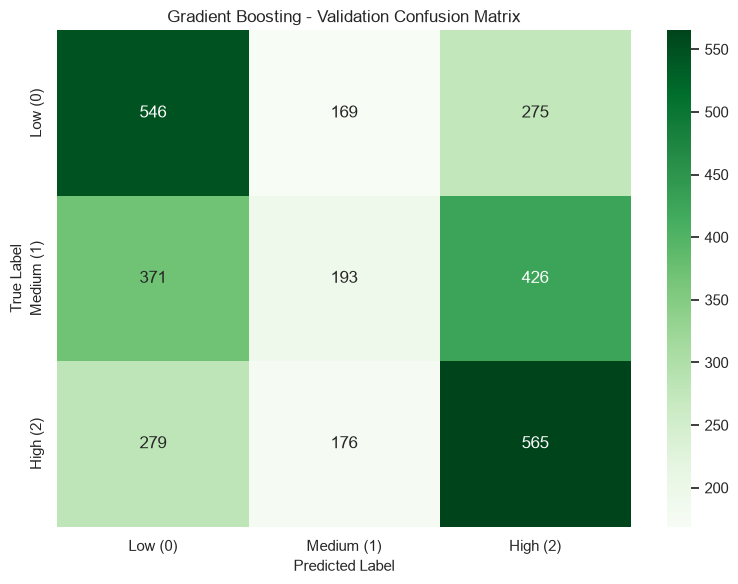

In [5]:
# -------------------------------------------------------------------------
# Visualizing the Confusion Matrix
# -------------------------------------------------------------------------
# Create a matplotlib figure to host the seaborn heatmap
plt.figure(figsize=(8, 6))

# Draw the heatmap, annotating cells with raw counts (fmt='d')
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)

# Add axis labels and title for academic clarity
plt.title("Gradient Boosting - Validation Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# Use tight_layout to prevent clipping of labels during image export
plt.tight_layout()

# Display the figure inline
plt.show()